In [1]:
## CL-2 (BI) Assignment 5: Machine Learning for Genomic Data
### Apply ML algorithms such as Random Forest and SVM to classify genomic data using genetic markers.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,ConfusionMatrixDisplay

In [3]:
rng=np.random.default_rng(42)
n_samples,n_markers=600,80
X=rng.integers(0,3,size=(n_samples,n_markers))
signal=1.2*X[:,3]+1.0*X[:,11]+0.9*X[:,27]-1.1*X[:,42]+0.8*X[:,58]+rng.normal(0,1.2,n_samples)
y=(signal>np.median(signal)).astype(int)
markers=[f"SNP_{i+1:03d}" for i in range(n_markers)]
df=pd.DataFrame(X,columns=markers); df["Class"]=y
display(df.head()); print("Shape:",df.shape); display(df.Class.value_counts().to_frame("count"))

,SNP_001,SNP_002,SNP_003,SNP_004,SNP_005,SNP_006,SNP_007,SNP_008,SNP_009,SNP_010,...,SNP_072,SNP_073,SNP_074,SNP_075,SNP_076,SNP_077,SNP_078,SNP_079,SNP_080,Class
0,0,2,1,1,1,2,0,2,0,0,...,0,1,0,2,1,0,0,1,2,1
1,2,1,0,2,1,2,0,0,2,2,...,0,2,0,1,1,0,1,1,2,1
2,2,1,1,1,1,2,0,0,1,0,...,2,0,2,1,2,1,1,0,1,0
3,0,1,0,1,1,0,2,1,2,0,...,2,0,0,0,1,2,2,2,2,0
4,0,0,1,2,2,0,0,0,0,1,...,0,1,1,2,2,0,0,0,0,1


Shape: (600, 81)


,count
Class,
1,300
0,300


Missing values: 0


,count,mean,std,min,25%,50%,75%,max
SNP_001,600.0,1.018333,0.822065,0.0,0.0,1.0,2.0,2.0
SNP_002,600.0,0.965000,0.821523,0.0,0.0,1.0,2.0,2.0
SNP_003,600.0,0.985000,0.834227,0.0,0.0,1.0,2.0,2.0
SNP_004,600.0,0.966667,0.814449,0.0,0.0,1.0,2.0,2.0
SNP_005,600.0,0.985000,0.822132,0.0,0.0,1.0,2.0,2.0
SNP_006,600.0,1.001667,0.826318,0.0,0.0,1.0,2.0,2.0
SNP_007,600.0,1.040000,0.822310,0.0,0.0,1.0,2.0,2.0
SNP_008,600.0,0.953333,0.819924,0.0,0.0,1.0,2.0,2.0
SNP_009,600.0,1.003333,0.817171,0.0,0.0,1.0,2.0,2.0
SNP_010,600.0,0.963333,0.818396,0.0,0.0,1.0,2.0,2.0


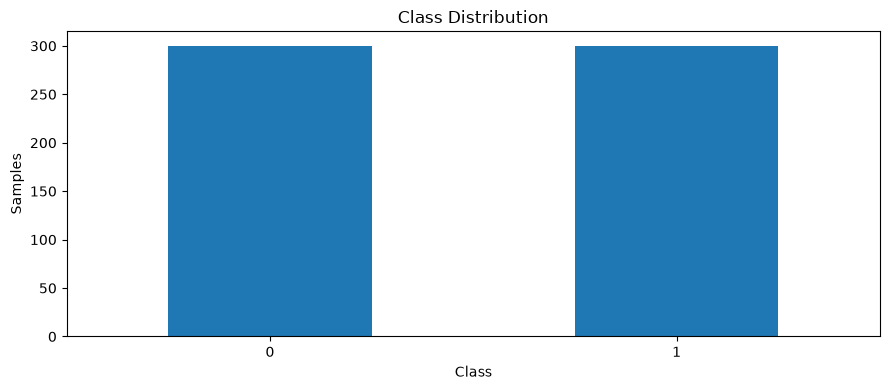

In [4]:
print("Missing values:",df.isna().sum().sum())
display(df[markers].describe().T.head(10))
plt.figure(figsize=(9,4)); df.Class.value_counts().sort_index().plot(kind="bar")
plt.title("Class Distribution"); plt.xlabel("Class"); plt.ylabel("Samples"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [5]:
X_train,X_test,y_train,y_test=train_test_split(df[markers],df.Class,test_size=.2,random_state=42,stratify=df.Class)
print("Training:",X_train.shape,"Testing:",X_test.shape)

Training: (480, 80) Testing: (120, 80)


In [6]:
# SVM Model Training
svm=Pipeline([("scaler",StandardScaler()),("model",SVC(kernel="rbf",random_state=42))])
svm.fit(X_train,y_train); svm_pred=svm.predict(X_test)
print(classification_report(y_test,svm_pred,digits=4))

              precision    recall  f1-score   support

           0     0.8214    0.7667    0.7931        60
           1     0.7812    0.8333    0.8065        60

    accuracy                         0.8000       120
   macro avg     0.8013    0.8000    0.7998       120
weighted avg     0.8013    0.8000    0.7998       120



In [7]:
# Random Forest Model Training
rf=RandomForestClassifier(n_estimators=300,random_state=42,class_weight="balanced")
rf.fit(X_train,y_train); rf_pred=rf.predict(X_test)
print(classification_report(y_test,rf_pred,digits=4))

              precision    recall  f1-score   support

           0     0.8361    0.8500    0.8430        60
           1     0.8475    0.8333    0.8403        60

    accuracy                         0.8417       120
   macro avg     0.8418    0.8417    0.8417       120
weighted avg     0.8418    0.8417    0.8417       120



,Accuracy,Precision,Recall,F1
SVM,0.8000,0.7812,0.8333,0.8065
Random Forest,0.8417,0.8475,0.8333,0.8403


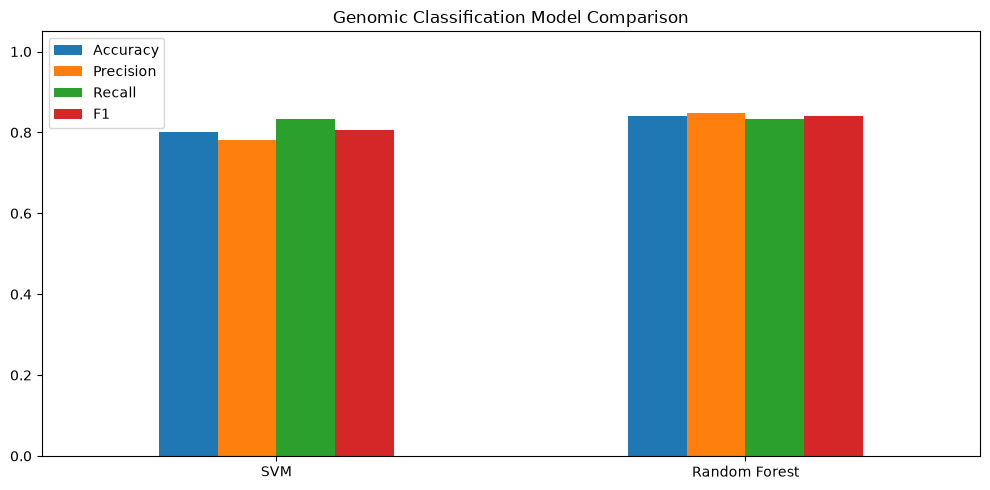

In [8]:
# Comparison of Models
def metric_row(y,p):
    return [accuracy_score(y,p),precision_score(y,p,zero_division=0),recall_score(y,p,zero_division=0),f1_score(y,p,zero_division=0)]
comparison=pd.DataFrame([metric_row(y_test,svm_pred),metric_row(y_test,rf_pred)],
 index=["SVM","Random Forest"],columns=["Accuracy","Precision","Recall","F1"])
display(comparison.round(4))
comparison.plot(kind="bar",figsize=(10,5)); plt.ylim(0,1.05); plt.title("Genomic Classification Model Comparison"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

,Importance
SNP_004,0.078414
SNP_043,0.050601
SNP_028,0.045092
SNP_012,0.044968
SNP_059,0.023739
SNP_055,0.013239
SNP_005,0.013117
SNP_069,0.012086
SNP_031,0.012034
SNP_046,0.011880


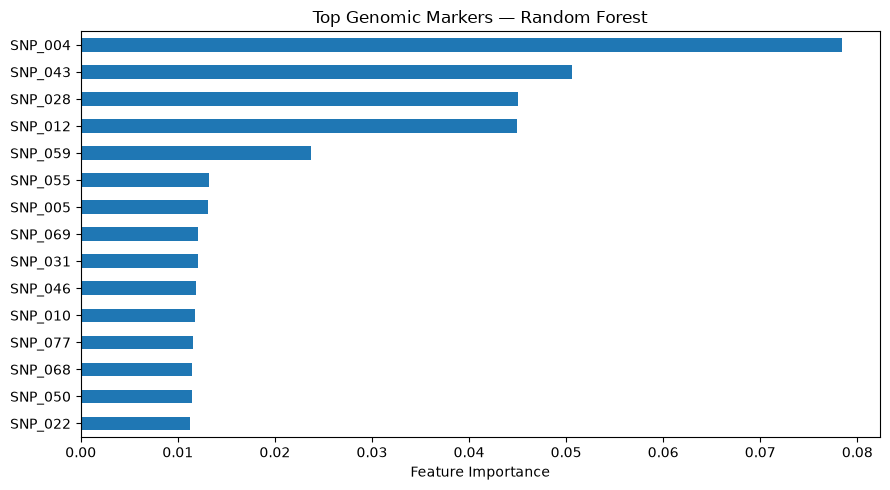

In [9]:
importance=pd.Series(rf.feature_importances_,index=markers).sort_values(ascending=False)
display(importance.head(15).to_frame("Importance"))
importance.head(15).sort_values().plot(kind="barh",figsize=(9,5))
plt.title("Top Genomic Markers — Random Forest"); plt.xlabel("Feature Importance"); plt.tight_layout(); plt.show()